Checking whether the transformations have worked correctly

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.cm as get_cmap
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec
import copy
from scipy.ndimage import gaussian_filter1d
from datetime import datetime
import pickle
import seaborn as sns
from scipy import stats
from scipy.interpolate import interp1d

In [2]:
runMac = 'yes'
dont_run_filter = True ## False = process the filtering steps and generate a pickle file with today's date. Takes ~ 70 mins. Else == True to pull saved pickle file. 
session = 'Syed3_noNP'
# session = 'Syed2'
# session = 'GNG_free_delay_noNP'
# session = 'GNG_free_delay'
# date_string = 250114 # if running pickle file, latest is 250214

In [3]:
main = Path(r'/Volumes/VS03-NandB-1/Eugenia/FSCV_Rat_Striatum_GoNogo/Data_analysis/R1_4/DLC/')
path = Path(main) / session / 'DLC_transformed'
fig_dir = Path(main) / session / 'Figures'

In [4]:
# Open transformed DLC coordinates
files = list(path.glob('*.h5')) # transformed DLC coordinates
DLCscorer = 'DLC_resnet50_BehSyl projectDec22shuffle1_100000'

In [5]:
# Get the animal IDs
animals = [file.stem for file in files]
animals = [name.replace('_tform_coords', '') for name in animals]

animal_dict = {}
# Iterate through the files to fill the dictionary 
for file in files:
    file_name = file.name  # Get the file name
    animal = file_name.split('_')[0]  # Extract the part before the first underscore
    # Store the animal as the key and the file name as the value in the dictionary
    animal_dict[animal] = file

# Combining the DLC and trigger files for each animal to use as a key later
df_paths = pd.DataFrame(list(animal_dict.items()), columns=['Animal', 'path_DLC'])

In [6]:
# Test that the files are loading correctly

testdf = pd.read_hdf(files[0])

testdf = testdf[1400:1800]
bodyparts=testdf.columns.get_level_values(1)[::3] #read out the header to get body part names!
print(bodyparts)
bodyparts2plot=bodyparts #you could also take a subset, i.e. =['snout']
scorer = testdf.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!


Index(['snout', 'neck', 'back1', 'back2', 'back3', 'back4', 'tailbase',
       'right paw', 'left paw'],
      dtype='object', name='bodyparts')


In [7]:
def get_cmap(n, name='viridis'):
    return plt.get_cmap(name, n)

def readDLCfiles(df_paths, animal='', path_DLC='path_DLC', path_trigger='path_trigger',):
    try:
        # Get the paths
        selected_pathDLC = df_paths.loc[df_paths['Animal'] == animal, path_DLC].values[0]
        selected_pathtrigger = df_paths.loc[df_paths['Animal'] == animal, path_trigger].values[0]

        df_DLC = pd.read_hdf(selected_pathDLC)
        df_trigger = pd.read_csv(selected_pathtrigger)
    except (IndexError, FileNotFoundError, KeyError) as e:
        print(f"Skipping animal {animal} due to missing data: {e}")
    return df_DLC, df_trigger


def getDLCwindow(df_DLC, df_trigger, pre_stimtime=10, post_stimtime=10, StimCategory='', PresentationNumber=1):
    """Get the trajectories for each animal, for each trial type
    
    Parameters:
    - df_DLC: DataFrame containing DLC data.
    - df_trigger: DataFrame containing trigger events.
    - pre_stimtime: Time in seconds to include before stimulus.
    - post_stimtime: Time in seconds to include after stimulus.
    - StimCategory: Category of stimulus to filter (if any).
    - PresentationNumber: The specific presentation number for the stimulus category.
    
    Returns:
    - df_DLC: The modified full DLC DataFrame windowed to the entire trial period.
    - df_subset: A subset of df_DLC centered around the stimulus.
    """
    fps = 29.97
    if not StimCategory:
        index = df_trigger[-1]
        # Determine the frame of the last stimulus
        stimtime = int(df_trigger.loc[index, 'VideoFrame'].item())

        start = int(np.floor(stimtime - (pre_stimtime * fps)))
        stop = int(np.ceil(stimtime + (post_stimtime * fps)))
        
        df_subset = df_DLC[start:stop]
            
    else:
        # Get the index to find the trialtype
        index = df_trigger[(df_trigger['StimCategory'] == StimCategory) & 
                        (df_trigger['PresentationNumber'] == PresentationNumber)].index

        stimtime = int(df_trigger.loc[index, 'VideoFrame'].item())
        start = int(np.floor(stimtime - (pre_stimtime * fps)))
        stop = int(np.ceil(stimtime + (post_stimtime * fps)))

        df_subset = df_DLC[start:stop]

    # get the last trial and add 120s
    whole_stop = int(df_trigger.iloc[-1]['VideoFrame'].item())

    whole_stop = whole_stop + int(120 * fps)
    whole_stop = int(np.ceil(whole_stop))

    df_DLC = df_DLC[:whole_stop]            

    return df_DLC, df_subset  

def getBPspeed(Dataframe, bodyparts2plot, animal=''):
    ''' 
    Plots the coordinates as linked line and gets the speedbp speed. 
    Returns a DataFrame with speed values for specified body parts.
    '''
    scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!

    df_copy = copy.deepcopy(Dataframe)

    bodypart_coords = {}
    # Run this for the raw values
    for bp in bodyparts2plot:
        bodypart_coords[bp] = np.vstack((df_copy[scorer][bp]['x'].values, df_copy[scorer][bp]['y'].values)).T 
        
        # Get the bodypart speed and plot it
        _, bp_speed = getSpeedy(bodypart_coords[bp])
        
        df_copy.loc[:, (scorer, bp, 'speed')] = bp_speed

    return df_copy
    
def getSpeedy(coordinates):   
    # Calculate the differences between consecutive points
    diffs = np.diff(coordinates, axis=0)
    
    # Use numpy's efficient vectorized norm to calculate distances
    distances = np.linalg.norm(diffs, axis=1)

    # Time array based on 29.97 FPS
    time = np.arange(len(distances)+1) / 29.97
    # time = time[1:]

    speed = distances / (1/29.97)
    speed = np.insert(speed, 0,0)

    return time, speed

def getDistance2speaker(Dataframe, scorer, animal):
    ''' To get the distances to speaker, saving it into the dataframe '''
    scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!
    df_copy = copy.deepcopy(Dataframe)

    # Define p1 and p2 as numpy arrays for vector operations
    if animal[0:6] == '223702':
        p1 = np.array([26.9, -0.5])
        p2 = np.array([26.9, 7.8])
    elif animal[0:6] == '191101':
        p1 = np.array([26.9, 15.1])
        p2 = np.array([26.9, 24.1])

    for bp in bodyparts2plot:
        # Access x and y values from the DataFrame
        x_values = df_copy[scorer][bp]['x']
        y_values = df_copy[scorer][bp]['y']

        # Stack x and y values to form a 2D array of coordinates
        xy = np.stack((x_values, y_values), axis=1)
        
        distances = []
        # Iterate over coordinates and calculate the distance
        for coord in xy:
            coord = np.array(coord)  # Ensure coord is a numpy array for vector operations
            d = (np.cross(p2 - p1, coord - p1) / np.linalg.norm(p2 - p1))
            distances.append(d)
        
        df_copy.loc[:, (scorer, bp, 'distance')] = distances

    return df_copy

def getOrientationAngle(Dataframe, scorer, animal):
    ''' Get the orientation of the rat relative to the speaker. Uses head and neck coordinates '''

    # neck
    xy1 = np.array([
        Dataframe[scorer]['neck']['x'],
        Dataframe[scorer]['neck']['y'],  
    ]).T

    # snout
    xy2 = np.array([
        Dataframe[scorer]['snout']['x'],
        Dataframe[scorer]['snout']['y'],
        
    ]).T
    
    x_wall = 26.9 # x coord of wall

    if animal[0:6] == '223702':
        y_range = [-15, 9.3]
    elif animal[0:6] == '191101':
        y_range = [15.4, 23.8]

    y_center = [x_wall, (max(y_range)+min(y_range))/2]

    # Calculate orientation angle
    big_angle = np.arctan2(xy2[:, 1] - xy1[:, 1], xy2[:, 0] - xy1[:, 0])  # in radians

    # Convert big_angle to degrees and normalize to 0-360 range
    big_angle_deg = np.degrees(big_angle) % 360  # Convert to degrees and wrap to [0, 360)

    # Calculate the y position where line intersects the x_wall
    x1_wall = x_wall - xy1[:, 0]
    y_crossing = xy1[:, 1] + np.tan(big_angle) * x1_wall  # crossing point along y-axis

    # Check if y_crossing falls within y_range
    x_crossing_in_range = (y_crossing >= y_range[0]) & (y_crossing <= y_range[1])
    condition = xy1[:,0]>xy2[:,0]
    x_crossing_in_range = np.where(condition & x_crossing_in_range, False, x_crossing_in_range)
    
    # Small angle for further use if needed, corrected for y_center
    small_angle = np.arctan2(x1_wall, y_crossing - y_center[1])  # in radians
    small_angle = np.degrees(small_angle) % 360  # Shift by 90 degrees for plotting, convert to degrees and wrap to [0, 360)

    return x_crossing_in_range, small_angle, big_angle_deg

def smooth_with_gaussian(data, window_size=9):
    ''' 
    Smooths data using a Gaussian window of a given size, similar to MATLAB's smoothdata(A, "gaussian", 9)
    
    Arguments:
    - data: 1D array or pandas Series of data to be smoothed
    - sigma: the size of the Gaussian window, similar to MATLAB's
    '''
    # Generate a Gaussian window
    sigma = (window_size-1) / 6  # To get 99 percentile of gaussian pdf = 6 * sigma
    smoothed_data  = gaussian_filter1d(data, sigma=sigma)
    return smoothed_data 

def find_nearest_valid(series, idx, max_search_distance=9):
    """
    Find the nearest valid (non-NaN) value in the series around the given idx.
    Searches to the left and right up to max_search_distance.
    """
    left_idx = idx - 1
    right_idx = idx + 1

    # Search to the left and right within the max_search_distance
    for n in range(1, max_search_distance + 1):
        if left_idx >= 0 and not pd.isna(series.iloc[left_idx]):
            return series.iloc[left_idx]
        if right_idx < len(series) and not pd.isna(series.iloc[right_idx]):
            return series.iloc[right_idx]
        left_idx -= 1
        right_idx += 1
    print(f"Had to use find_nearest_valid")

    # Return NaN if no valid value is found within the search distance
    return float('nan')

def filter_coord(Dataframe, bodyparts2plot, pcutoff=0.3, method=1):
    f_Dataframe = copy.deepcopy(Dataframe)

    for bp in bodyparts2plot:
        scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!
        x_values = f_Dataframe[scorer][bp]['x'].copy()
        y_values = f_Dataframe[scorer][bp]['y'].copy()
        likelihood = f_Dataframe[scorer][bp]['likelihood'].copy()
        
        # Convert x and y values into arrays for processing
        xy = np.vstack((x_values, y_values)).T
        _, bp_speed = getSpeedy(xy)

        keep_indices = np.ones(len(bp_speed), dtype=bool)
            
        # ------------------------------
        # Filter based on likelihood cutoff
        # ------------------------------
        for idx in range(len(likelihood)):
            if likelihood.iloc[idx] < pcutoff:
                # Mark points with low likelihood for exclusion
                keep_indices[idx] = False

        if method == 1:
            median_speed = np.nanmedian(bp_speed)
            std_speed = np.nanstd(bp_speed)
            exclude_speed = median_speed + 2 * std_speed

            # ------------------------------
            # Filter based on speed cutoff
            # ------------------------------
            for idx in range(1, len(bp_speed) - 1):
                if bp_speed[idx] > exclude_speed:
                    keep_indices[max(0, idx-1):min(len(bp_speed), idx+2)] = False # Mark t-1, t, and t+1 for exclusion

            # ------------------------------------------------------
            # Filter based on large movements in x and y coordinates
            # ------------------------------------------------------                
            indices_x = np.abs(x_values.diff()) > 1.5
            indices_y = np.abs(y_values.diff()) > 1.5

            # merge these indices
            merged_indices = indices_x | indices_y

            # apply the merged indices
            keep_indices[~merged_indices] = False
            
        else:            
            if method == 3:
            # ------------------------------------------------------
            # Filter based on large movements in x and y coordinates
            # ------------------------------------------------------                
                indices_x = np.abs(x_values.diff()) > 1.5
                indices_y = np.abs(y_values.diff()) > 1.5

                # merge these indices
                merged_indices = indices_x | indices_y

                # apply the merged indices
                keep_indices[~merged_indices] = False

            # --------------------------------------------------------------------
            # Filter based on dynamic speed cutoff within the moving window
            # --------------------------------------------------------------------
            # Define the window size for the moving filter
            window = 9
            half_window = window // 2

            for idx in range(len(bp_speed)):
                # Define the start and end indices for the window around the current index
                start_idx = max(0, idx - half_window)
                end_idx = min(len(bp_speed), idx + half_window + 1)
                
                # Extract the speed values within the current window
                window_speeds = bp_speed[start_idx:end_idx]
                
                # Calculate local median and standard deviation within the window
                local_mean = np.nanmean(window_speeds)
                local_std = np.nanstd(window_speeds)
                local_cutoff = local_mean + 2 * local_std

            # ------------------------------
            # Filter based on speed cutoff
            # ------------------------------
                # Check if the speed at the current index exceeds the local cutoff
                if bp_speed[idx] > local_cutoff:
                    # Mark the entire window for exclusion if the condition is met
                    keep_indices[start_idx:end_idx] = False            


        # ------------------------------
        # Interpolate data and gaussian smooth
        # ------------------------------
        for idx in range(2, len(bp_speed) - 2):
            # if not keep_indices[idx]:
            #     # Interpolate x and y coordinates separately using neighbors at t-2 and t+2
            #     x_values.iloc[idx] = (x_values.iloc[idx-2] + x_values.iloc[idx+2]) / 2.0
            #     y_values.iloc[idx] = (y_values.iloc[idx-2] + y_values.iloc[idx+2]) / 2.0
            #     keep_indices[idx] = True  # After interpolation, mark as valid

            if not keep_indices[idx]:
                # Search for the nearest valid values in both directions
                valid_x_left = find_nearest_valid(x_values, idx - 2)
                valid_x_right = find_nearest_valid(x_values, idx + 2)

                # Interpolate only if both neighbors are found
                if not pd.isna(valid_x_left) and not pd.isna(valid_x_right):
                    x_values.iloc[idx] = (valid_x_left + valid_x_right) / 2.0
                elif not pd.isna(valid_x_left):  # Use the left value if only left is valid
                    x_values.iloc[idx] = valid_x_left
                elif not pd.isna(valid_x_right):  # Use the right value if only right is valid
                    x_values.iloc[idx] = valid_x_right
                
                # Repeat the same for y_values
                valid_y_left = find_nearest_valid(y_values, idx - 2)
                valid_y_right = find_nearest_valid(y_values, idx + 2)

                if not pd.isna(valid_y_left) and not pd.isna(valid_y_right):
                    y_values.iloc[idx] = (valid_y_left + valid_y_right) / 2.0
                elif not pd.isna(valid_y_left):
                    y_values.iloc[idx] = valid_y_left
                elif not pd.isna(valid_y_right):
                    y_values.iloc[idx] = valid_y_right
                
                keep_indices[idx] = True  # After interpolation, mark as valid
                
        # ------------------------------
        # Apply Gaussian smoothing to the x and y coordinates
        # ------------------------------
        # Preserve the index before applying smoothing
        original_index = x_values.index
        
        smoothed_x_values = smooth_with_gaussian(x_values, window_size=9)
        smoothed_y_values = smooth_with_gaussian(y_values, window_size=9)
        
        # Recreate pandas Series with the original index to preserve row titles
        smoothed_x_values = pd.Series(smoothed_x_values, index=original_index)
        smoothed_y_values = pd.Series(smoothed_y_values, index=original_index)
        
        # ------------------------------
        # Update the f_Dataframe with the filtered and smoothed values
        # ------------------------------
        # Use .loc to update the x and y values in the DataFrame
        f_Dataframe.loc[:, (scorer, bp, 'x')] = smoothed_x_values
        f_Dataframe.loc[:, (scorer, bp, 'y')] = smoothed_y_values
        f_Dataframe.loc[:, (scorer, bp, 'time')] = range(1, len(f_Dataframe) + 1)
        
    # Return the shape of the interpolated data
    return f_Dataframe

# ------------------------      PLOTTING      ------------------------                     
def PlotBodyParts(ax, x_values, y_values, color, alphavalue=.2):
    ''' To plot the bodyparts '''
    midpoint = int(len(x_values)/2)
    ax[0].plot(x_values, y_values, color=color, alpha=alphavalue)        
    # Draw a star at the start of the trajectory
    ax[0].scatter(x_values[0], y_values[0], color=color, marker='*', s=100)
    ax[0].scatter(x_values[midpoint], y_values[midpoint], color=color, marker='+', s=100)    

def PlottingTrajSpeed(Dataframe, bodyparts2plot, animal='', alphavalue=.2, colormap='jet', speedbp='', StimCategory='', PresentationNumber=1, title =''):
    ''' Plots the coordinates as linked line and get the speedbp speed. '''
    colors = get_cmap(len(bodyparts2plot), name=colormap)
    scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!
    
    bodypart_coords = {}
    
    fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))

    # Run this for the raw values
    for bp in bodyparts2plot:
        bodypart_coords[bp] = np.vstack((Dataframe[scorer][bp]['x'].values, Dataframe[scorer][bp]['y'].values)).T
        color = colors(bodyparts2plot.get_loc(bp))

        x_values = Dataframe[scorer][bp]['x'].values
        y_values = Dataframe[scorer][bp]['y'].values        
                
        PlotBodyParts(ax, x_values, y_values, color, alphavalue=alphavalue)

        ax[0].invert_yaxis()  
        ax[0].set_xlim(-20,35)
        ax[0].set_ylim(-20,35)

        if title == '':
            if not StimCategory:
                ax[0].set_title(f'{animal} trajectory')
            else:
                ax[0].set_title(f'{animal}: #{PresentationNumber} {StimCategory} trajectory')

        # if manually defining title names
        else:
            ax[0].set_title(f'{title} trajectory', fontsize = 'small')

        ax[0].set_xlabel('cm', labelpad=0.1)
        ax[0].set_ylabel('cm', labelpad=0.1)
        rect = patches.Rectangle((0, 0), 26.9, 31.8, linewidth=2, edgecolor='r', facecolor='none')
        ax[0].add_patch(rect)
        
        if speedbp == '':
        # Get bodyparts speed and plot them
            time, bp_speed = getSpeedy(bodypart_coords[bp])
            ax[1].plot(time, bp_speed, label=bp, color=color)  # Plot each body part's filtered speed
            ax[1].set_ylabel('speed [cm/s]', labelpad=0.1)
            ax[1].set_xlabel('time [s]', labelpad=0.1)
            ax[1].vlines(x=10, ymin=-3, ymax=max(bp_speed), linestyles=':', colors='k')

            if title == '':
                ax[1].set_title(f'{animal}: speed of all body parts')                           
            else:
                ax[1].set_title(f'{title}: speed of all body parts', fontsize = 'small') # if manually defining title names 

            textstr = '\n'.join((
            r'$\mathrm{frame1}=%.0f$' % (Dataframe.index[0], ),
            r'$\mathrm{frame-1}=%.0f$' % (Dataframe.index[-1], )))
                
            # these are matplotlib.patch.Patch properties
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
            
            ax[1].text(0.05, 0.95, textstr, transform=ax[1].transAxes, fontsize=10,
            verticalalignment='top', bbox=props)

    if speedbp != '':
        time, bp_speed = getSpeedy(bodypart_coords[speedbp])
        ax[1].plot(time, bp_speed, label=bp, color=color)  # Plot each body part's filtered speed
        ax[1].set_ylabel('speed [cm/s]', labelpad=0.1)
        ax[1].set_xlabel('time [s]', labelpad=0.1)
        ax[1].vlines(x=10, ymin=-3, ymax=max(bp_speed), linestyles=':', colors='k')

        if title == '':
            ax[1].set_title(f'{animal}: {speedbp} speed')
        else: 
            ax[1].set_title(f'{title} {speedbp} speed', fontsize = 'small')    # if manually defining title names

        textstr = '\n'.join((
        r'$\mathrm{first}=%.0f$' % (Dataframe.index[0], ),
        r'$\mathrm{last}=%.0f$' % (Dataframe.index[-1], )))
            
        # these are matplotlib.patch.Patch properties
        props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
        
        ax[1].text(0.05, 0.95, textstr, transform=ax[1].transAxes, fontsize=10,
        verticalalignment='top', bbox=props)
    
def PlottingVar2Speaker(Dataframe, animal, title=''):
    scorer = Dataframe.columns.get_level_values(0)[0]  # Read out the header to get the scorer name!

    fig, ax2 = plt.subplots(2, 1, figsize=(6, 7))
    
    # distances = PlotDist2Speaker(Dataframe, scorer, animal)
    distances = Dataframe[scorer]['snout']['distance']
    time = np.arange(len(distances)) / 29.97

    ax2[0].plot(time, distances, color='royalblue')
    ax2[0].hlines(y=0, xmin=0,xmax=max(time), linestyles=':', colors='k')
    ax2[0].vlines(x=10, ymin=-3, ymax=40, linestyles=':', colors='k')
    if title=='':
        ax2[0].set_title('Orientation to speaker')
    else:
        ax2[0].set_title(f"{title} Orientation to speaker")


    ax2[0].set_title(f"{animal} Snout distance to speaker")
    ax2[0].set_xlabel('time [s]', labelpad=0.1)
    ax2[0].set_ylabel('Distance from speaker [cm]', labelpad=0.1)
    ax2[0].grid(False)  # Remove grid

    # Plot the orientation
    x_crossing_in_range, _, angle = getOrientationAngle(Dataframe, scorer, animal)

    # ---------------------------------------------------
    # Plot the angle over time on the first y-axis
    ax2[1].plot(time, angle, label='small_angle', color='royalblue')
    ax2[1].vlines(x=10, ymin=0, ymax=360, linestyles=':', colors='k')
    ax2[1].set_xlabel('Timepoints')
    ax2[1].set_ylabel('Head Angle (degrees)', color='royalblue')
    ax2[1].tick_params(axis='y', labelcolor='royalblue')
    ax2[1].grid(False)  # Remove grid
    if title=='':
        ax2[1].set_title('Orientation to speaker')
    else:
        ax2[1].set_title(f"{title} Orientation to speaker")

    # Create a second y-axis for the boolean shading
    ax3 = ax2[1].twinx()
    ax3.set_ylabel('Oriented to Speaker (1=True)', color='green')
    ax3.tick_params(axis='y', labelcolor='green')
    ax3.grid(False)  # Remove grid

    # Plot a shaded area where x_crossing_in_range is True
    ax3.fill_between(
        time, # x-axis
        0, 
        1, 
        where=x_crossing_in_range, 
        color='green', 
        alpha=0.30, 
        label='x_crossing_in_range'
    )

    # Add legends for clarity
    fig.tight_layout()
    return distances

def save_figure(fig_dir, name, figure, folder_name='', saving = False):
    '''    Saves a given figure with a specific naming convention based on the parameters provided. '''
    if saving == True:
        today_date = datetime.now().strftime('%y%m%d')  # Format: DDMMYY
        if folder_name == '':
            fig_folder = os.path.join(fig_dir, today_date) # Create the folder if it doesn't exist
            os.makedirs(fig_folder, exist_ok=True)

            # Full path for saving the figure
            fig_path = os.path.join(fig_folder, name)

            # Save the figure
            figure.savefig(fig_path)
        else:
            fig_folder = os.path.join(fig_dir, today_date) # Create the folder if it doesn't exist
            os.makedirs(fig_folder, exist_ok=True)
            sub_folder = os.path.join(fig_folder, folder_name) # Create the folder if it doesn't exist
            os.makedirs(sub_folder, exist_ok=True)

            # Full path for saving the figure
            fig_path = os.path.join(sub_folder, name)

            # Save the figure
            figure.savefig(fig_path)


In [8]:
def readDLCfiles(df_paths, animal='', path_DLC='path_DLC'):
    try:
        # Get the paths
        selected_pathDLC = df_paths.loc[df_paths['Animal'] == animal, path_DLC].values[0]
        

        df_DLC = pd.read_hdf(selected_pathDLC)
        
    except (IndexError, FileNotFoundError, KeyError) as e:
        print(f"Skipping animal {animal} due to missing data: {e}")

    return df_DLC

In [9]:
df_DLC = {}
for index, row in df_paths.iterrows():
    animal = animals[index]
    df_DLC[animal] = readDLCfiles(df_paths, animal=animal, path_DLC='path_DLC')


Index(['snout', 'neck', 'back1', 'back2', 'back3', 'back4', 'tailbase',
       'right paw', 'left paw'],
      dtype='object', name='bodyparts')


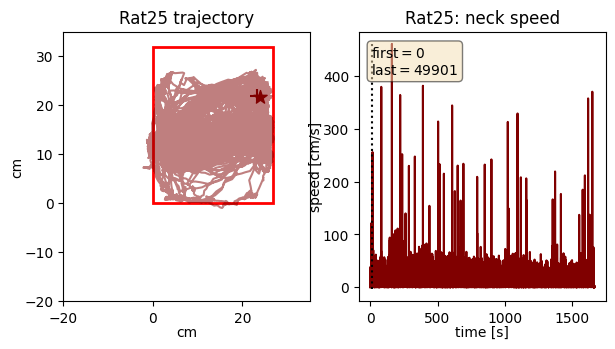

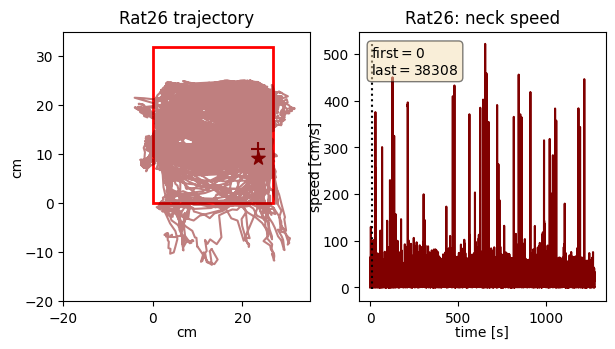

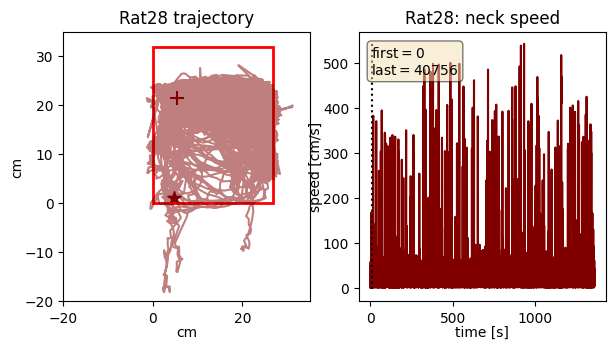

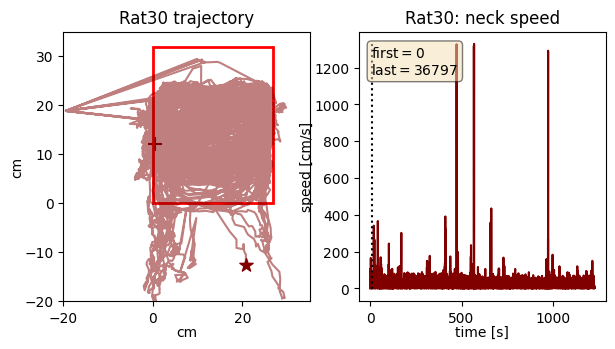

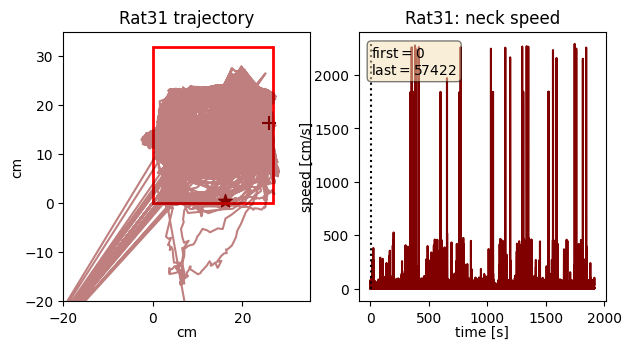

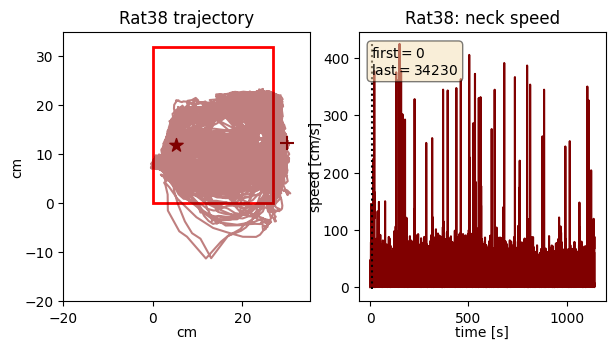

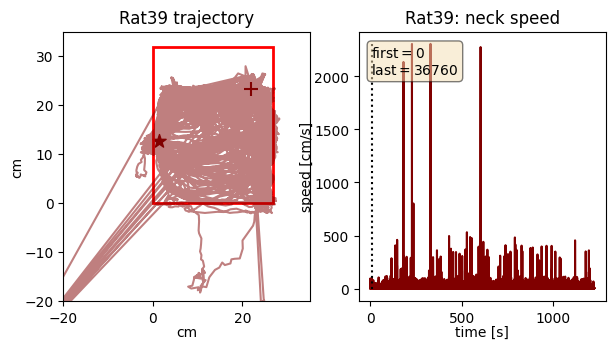

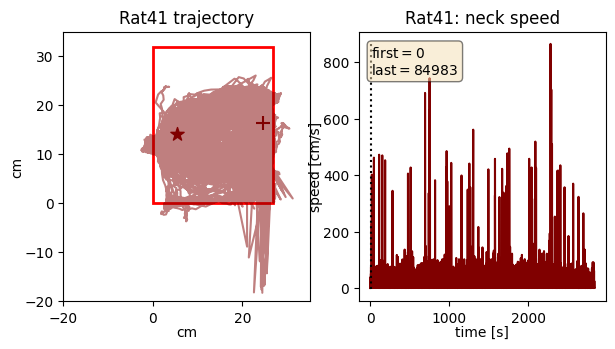

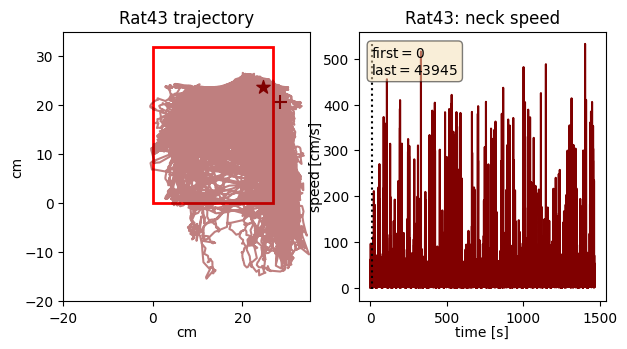

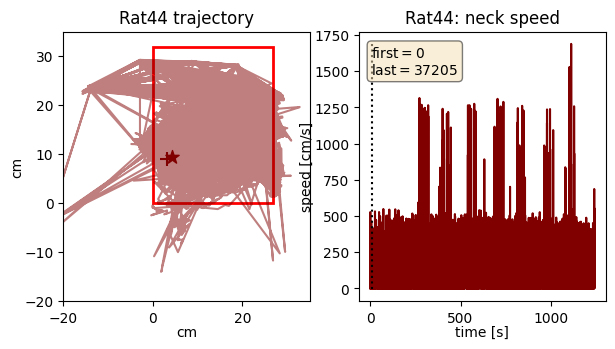

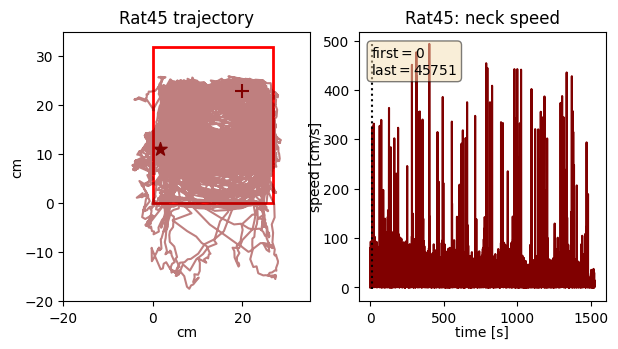

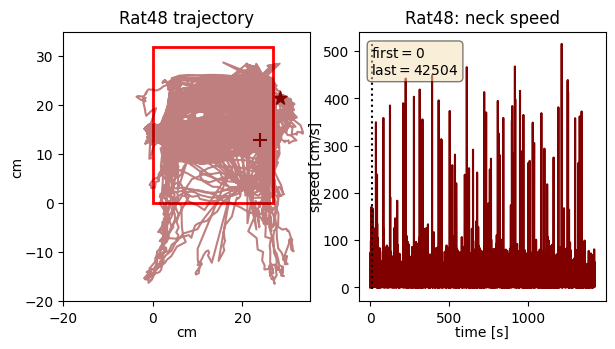

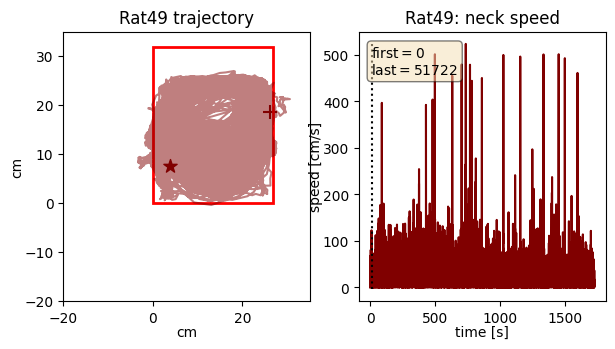

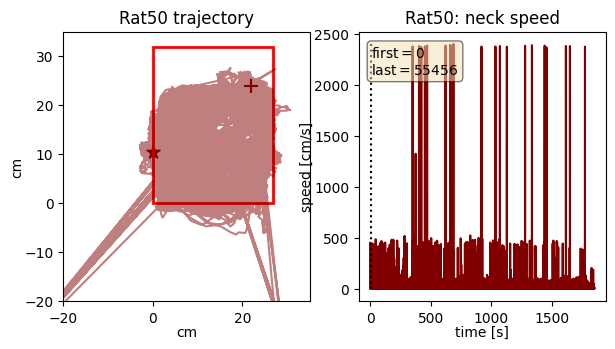

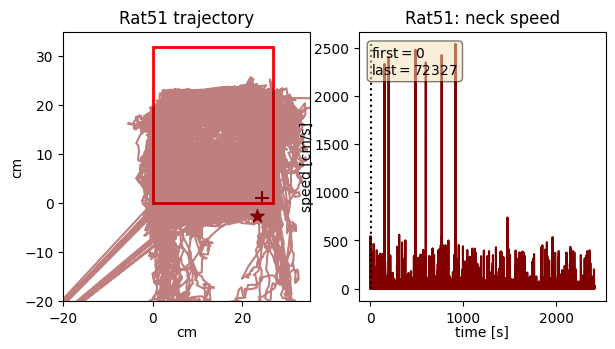

In [10]:
bodyparts=testdf.columns.get_level_values(1)[::3] #read out the header to get body part names!
print(bodyparts)
bodyparts2plot=bodyparts[1:2]
bp2plot_speed = bodyparts2plot[0]
# animal = 'Rat10'
for animal in animals:
    PlottingTrajSpeed(df_DLC[animal], bodyparts2plot, animal=animal, 
                            alphavalue=.5, speedbp=bp2plot_speed)